# Historia 5 — Ilu mieszkańców trzeba zapytać o samochód?

Miasto liczy **100 000 mieszkańców**. Dane o posiadaniu samochodu wyglądają tak:

| Obszar | Liczba mieszkańców | Osoby posiadające samochód |
|---|---:|---:|
| Miejski | 50 000 | 75% |
| Podmiejski | 30 000 | 60% |
| Wiejski | 20 000 | 40% |

**Cel:** ustalić potrzebną liczbę ankietowanych przy **95% poziomie ufności** i dokładności **do 3 punktów procentowych**.

Porównamy wynik uzyskany osobno dla każdego obszaru z wynikiem dla jednego odsetka dla całego miasta.

### Przygotowanie
Wczytujemy biblioteki potrzebne do obliczeń i wykresów.

In [9]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

### Krok 1. Wprowadzamy dane
Wpisujemy liczbę mieszkańców i szacowany procent właścicieli samochodów w każdym obszarze.

In [10]:
nazwy5 = ["Miejski", "Podmiejski", "Wiejski"]
populacje5 = np.array([50_000, 30_000, 20_000], dtype=int)
proporcje5 = np.array([0.75, 0.60, 0.40])
N5 = int(populacje5.sum())
z5 = stats.norm.ppf(0.975)
E5 = 0.03
wariancje5 = proporcje5 * (1 - proporcje5)

print(f"Populacja: {N5:,} osób")
print(f"Docelowy margines błędu: ±{E5:.0%} = ±3 punkty procentowe")

Populacja: 100,000 osób
Docelowy margines błędu: ±3% = ±3 punkty procentowe


### Krok 2. Liczymy próbę osobno dla każdego obszaru
Sprawdzamy, ile osób należy zapytać w każdej grupie. Na końcu dodajemy wyniki.

In [11]:
n_warstwy5 = np.ceil((z5**2 * wariancje5) / E5**2).astype(int)
n_pdf5 = int(n_warstwy5.sum())

tabela5_pdf = pd.DataFrame({
    "Typ dzielnicy": nazwy5,
    "Populacja": populacje5,
    "Odsetek właścicieli": proporcje5,
    "Próba dla osobnego błędu ±0,03": n_warstwy5,
})
display(tabela5_pdf)
print(f"Łączna próba z sumowania trzech osobnych wymagań: {n_pdf5} osób")

,Typ dzielnicy,Populacja,Odsetek właścicieli,"Próba dla osobnego błędu ±0,03"
0,Miejski,50000,0.75,801
1,Podmiejski,30000,0.60,1025
2,Wiejski,20000,0.40,1025


Łączna próba z sumowania trzech osobnych wymagań: 2851 osób


### Krok 3. Liczymy próbę dla całego miasta
Teraz chcemy otrzymać tylko jeden wynik dla wszystkich mieszkańców. Program dzieli ankietowanych między trzy obszary odpowiednio do ich wielkości. Najpierw przygotujemy potrzebne funkcje.

In [12]:
def alokuj_proporcjonalnie(n, populacje):
    # Dzielimy osoby odpowiednio do wielkości grup.
    populacje = np.asarray(populacje, dtype=int)
    udzialy = populacje / populacje.sum()
    idealne = n * udzialy
    przydzial = np.floor(idealne).astype(int)
    brakuje = n - przydzial.sum()
    kolejnosc = np.argsort(-(idealne - przydzial), kind="stable")
    przydzial[kolejnosc[:brakuje]] += 1
    return przydzial


def margines_warstwowy(przydzial, populacje, wariancje, z):
    # Sprawdzamy dokładność wyniku dla całej populacji.
    przydzial = np.asarray(przydzial, dtype=float)
    populacje = np.asarray(populacje, dtype=float)
    wariancje = np.asarray(wariancje, dtype=float)
    if np.any(przydzial == 0) or np.any(przydzial > populacje):
        return float("inf")
    wagi = populacje / populacje.sum()
    wariancja_estymatora = np.sum(wagi**2 * (1/przydzial - 1/populacje) * wariancje)
    return z * np.sqrt(max(wariancja_estymatora, 0))

In [13]:
def minimalna_proba_proporcjonalna(populacje, wariancje, z, E):
    # Szukamy potrzebnej liczby osób.
    N = int(np.sum(populacje))
    wagi = np.asarray(populacje) / N
    A = np.sum(wagi * np.asarray(wariancje))
    n0 = (z**2 * A) / E**2
    n_fpc = n0 / (1 + n0 / N)
    n = max(len(populacje), math.ceil(n_fpc))

    def blad_dla(n_test):
        alokacja = alokuj_proporcjonalnie(n_test, populacje)
        return margines_warstwowy(alokacja, populacje, wariancje, z)

    while blad_dla(n) > E:
        n += 1
    while n > len(populacje) and blad_dla(n - 1) <= E:
        n -= 1
    return n0, n_fpc, n, alokuj_proporcjonalnie(n, populacje), blad_dla(n)

In [14]:
n0_5, nfpc_5, n_global5, podzial5, margines_global5 = minimalna_proba_proporcjonalna(
    populacje5, wariancje5, z5, E5
)

p_miasta5 = np.sum((populacje5 / N5) * proporcje5)
print(f"Szacowany udział właścicieli aut w całym mieście: {p_miasta5:.2%}")
print(f"Próba bez korekty FPC: {n0_5:.2f}")
print(f"Próba z korektą FPC (przed zaokrągleniem): {nfpc_5:.2f}")
print(f"Minimalna próba dla udziału całego miasta: {n_global5}")
print(f"Przydział: {dict(zip(nazwy5, podzial5))}")
print(f"Margines błędu po przydziale: ±{margines_global5:.4%}")
assert sum(podzial5) == n_global5 and margines_global5 <= E5

Szacowany udział właścicieli aut w całym mieście: 63.50%
Próba bez korekty FPC: 912.35
Próba z korektą FPC (przed zaokrągleniem): 904.10
Minimalna próba dla udziału całego miasta: 905
Przydział: {'Miejski': np.int64(453), 'Podmiejski': np.int64(271), 'Wiejski': np.int64(181)}
Margines błędu po przydziale: ±2.9987%


### Krok 4. Porównujemy wyniki na wykresie
Wykres pokazuje, jak różna może być liczba ankietowanych w zależności od tego, czy potrzebujemy wyników dla każdej dzielnicy osobno, czy dla miasta jako całości.

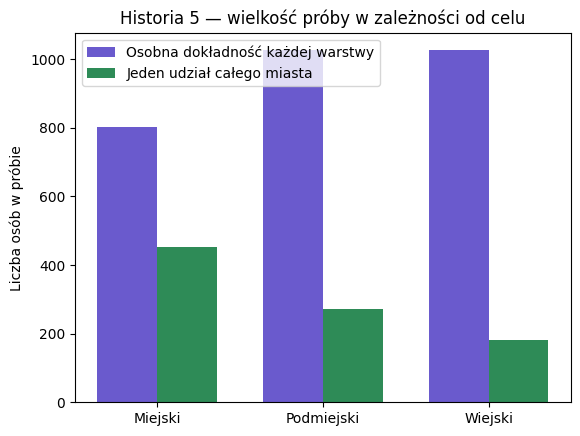

In [15]:
pozycje5 = np.arange(len(nazwy5))
fig, ax = plt.subplots()
ax.bar(pozycje5 - 0.18, n_warstwy5, width=0.36, color="slateblue", label="Osobna dokładność każdej warstwy")
ax.bar(pozycje5 + 0.18, podzial5, width=0.36, color="seagreen", label="Jeden udział całego miasta")
ax.set_xticks(pozycje5, nazwy5)
ax.set(ylabel="Liczba osób w próbie", title="Historia 5 — wielkość próby w zależności od celu")
ax.legend()
plt.show()

### Wniosek
Według sposobu liczenia **osobno dla każdego obszaru** potrzeba **2851 mieszkańców**. Jeśli chcemy poznać tylko **jeden odsetek dla całego miasta**, wystarcza około **905 osób** przy proporcjonalnym wyborze respondentów. Na podstawie podanych danych szacowany udział właścicieli samochodów w mieście to **63,5%**.